[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/BMED365-2027/blob/main/Lab-QuickStart/notebooks/quickstart-ai-python.ipynb)

*BMED365 — Computational Imaging, Modeling and AI in Biomedicine (Spring 2027) · Updated by A. Lundervold*

# Quick Start: AI-Assisted Python Programming *with Productive Friction*

Welcome to your hands-on gateway into **Python**, **scientific computing**, and **thinking alongside AI** in biomedicine!

In this session you will learn:
- How to run and edit **Jupyter Notebooks** in **Google Colab** (or locally with `uv` and the `bmed365-2027` kernel)
- Core **Python building blocks** (`variables`, `types`, `lists`, `if/else`, `for` loops, `functions`, and 2D `NumPy` image arrays)
- How to work with **AI assistants** (*Centaur* and *Cyborg* modes) **without losing your own clinical and scientific judgment**
- Concrete mini-previews of **BMED365**:
  - **Lab 0 (Machine Learning):** Tabular classification & the generalization check
  - **Lab 1 (Network Science):** Patient Similarity Networks (`NetworkX`)
  - **Labs 4 & 5 (The Kiwi 7T MRI Challenge):** Reading a real 16-bit MRI slice, seeing why naive AI/thresholding fails, computing 3D voxel volumes (`mm³`), and testing a 1-line biophysical organ-growth model

---

**Target audience:** Medical and biomedicine students (BSc/MSc/MD/PhD) — zero prior programming required  
**Session:** Tuesday, January 12, 2027, 09:15–13:00 (Room `9a110bp`)

---

### How to Use Our Four Learning Icons

Research in cognitive science and medical AI education shows that **passive copy-pasting from AI creates an illusion of competence** (*cognitive offloading* and *never-skilling*), whereas **brief, structured struggle** wires lasting understanding:

- 🧠 **Predict First!** Pause for 15 seconds and guess what the code will output *before* pressing `Shift+Enter`.
- 🎯 **Your Turn!** Spend 2 minutes writing or modifying code yourself *before* opening hints or asking AI.
- 🔍 **Friction Check / Graduated Hints:** Click the `▶` triangle on `<details>` blocks only *after* your own attempt.
- 🤖 **AI Partner Prompt:** Prompts designed for *Socratic coaching* and *critical verification* rather than blind answer-dumping.

---

# Module 1: Welcome, Setup & How We Learn with AI (09:15–09:45)

## Why Learn Python When AI Can Write Code?

In *[Co-Existence: The Next Phase of AI](https://co-existence.ai/)* (2026), Ethan Mollick notes a central paradox of modern AI:
1. **AI capability is a *jagged frontier*:** The same model that writes clean Python plots can silently mix up clinical units (`cm` vs. `m`), leak test patients into training data, or hallucinate lesion counts on an MRI slice.
2. **Syntax is cheap; *judgment* is the bottleneck:** You do not need to memorize every library option, but you *do* need enough Python and biomedical understanding to **specify what you want, read the code, and reality-check the output**.
3. **Coding is where *reality checks the AI*:** Unlike an essay, Python code can be tested immediately against numbers, units, edge cases, and real biomedical data.

## Jupyter Notebooks: Google Colab & Local `uv`

This file (`.ipynb`) is a **Jupyter Notebook** combining:
- **Markdown text cells** (explanations, clinical notes, and $\LaTeX$ math like $\text{BMI} = w / h^2$)
- **Executable Python code cells** — run any selected cell with **`Shift + Enter`** (or click the ▶ button)

> 💡 **Running in Google Colab?** Choose **File → Save a copy in Drive** first so your own experiments are saved.

In [1]:
# ============================================================================
# YOUR FIRST LINE OF PYTHON CODE!
# ============================================================================
# Lines starting with # are comments for humans — Python ignores them.
# Press Shift+Enter to execute this cell:

print("Hello, BMED365! Ready for computational biomedicine.")

Hello, BMED365! Ready for computational biomedicine.


🎉 **It runs!** `print(...)` is a built-in **function** that displays text or numbers on the screen. Text strings are surrounded by quotation marks (`"..."` or `'...'`).

### 🎯 Your Turn!
Edit the cell below so it prints your own name and one biomedical topic you are curious about (e.g., brain MRI, genetics, heart physiology, clinical AI):

In [2]:
# Edit the text inside the quotation marks and press Shift+Enter:
print("Hi, my name is [YOUR NAME], and I am curious about [TOPIC]!")

Hi, my name is [YOUR NAME], and I am curious about [TOPIC]!


In [3]:
# ============================================================================
# ENVIRONMENT & HARDWARE CHECK (Works in Google Colab AND Local uv!)
# ============================================================================
import platform
import sys

try:
    import google.colab  # type: ignore
    IN_COLAB = True
    env_label = "Google Colab (cloud runtime)"
except ImportError:
    IN_COLAB = False
    env_label = "Local Python / uv environment (bmed365-2027)"

# Check optional GPU acceleration (CUDA on NVIDIA, MPS on Apple Silicon, else CPU)
device = "cpu"
try:
    import torch
    if torch.cuda.is_available():
        device = f"cuda ({torch.cuda.get_device_name(0)})"
    elif torch.backends.mps.is_available():
        device = "mps (Apple Silicon GPU)"
except ImportError:
    pass

print(f"Environment : {env_label}")
print(f"Python      : {sys.version.split()[0]} ({platform.system()} {platform.machine()})")
print(f"Compute     : {device}")

Environment : Local Python / uv environment (bmed365-2027)
Python      : 3.12.2 (Darwin arm64)
Compute     : mps (Apple Silicon GPU)


### 🧠 Predict First! (Text vs. Numbers)

Look closely at the two `print` lines below **before** running the cell.
- What will `120 + 80` output?
- What will `"120" + "80"` output — `200`, an error, or something else?

In [4]:
# Predict first, then press Shift+Enter!
print("As numbers :", 120 + 80)
print("As text    :", "120" + "80")

As numbers : 200
As text    : 12080


<details>
<summary><b>🔍 Friction Check — Why did Python print <code>12080</code>?</b></summary>

When digits are inside quotation marks (`"120"`), Python treats them as **text characters (`str`)**, so `+` glues the two pieces of text together (*concatenation*). Without quotes (`120`), Python treats them as **numbers (`int`)** and adds them mathematically. Spotting data types early prevents subtle bugs when loading hospital spreadsheets!
</details>

---

# Module 2: Python Building Blocks for Biomedicine (09:45–10:30)

Almost every biomedical analysis in Python is built from six small pieces:
1. **Variables** — naming values so code reads like plain English
2. **Calculations** — clinical and physical formulas with explicit units
3. **Data types** — text (`str`), whole numbers (`int`), decimals (`float`), and truth values (`bool`)
4. **Lists** — ordered sequences of measurements (with `0`-based indexing!)
5. **Conditions (`if / elif / else`)** — clinical decision rules and thresholds
6. **Loops (`for`) & Functions (`def`)** — repeating a rule cleanly across many patients

## 2.1 Variables — Naming Clinical Quantities

We use `=` to **assign** a value to a descriptive variable name (always include units in the name or a comment!):

In [6]:
# Create variables for a fictional patient
patient_name = "Kari Hansen"
patient_age_yr = 67
weight_kg = 72.5
height_m = 1.68

print("Patient :", patient_name)
print("Age     :", patient_age_yr, "years")
print("Weight  :", weight_kg, "kg")
print("Height  :", height_m, "m")

Patient : Kari Hansen
Age     : 67 years
Weight  : 72.5 kg
Height  : 1.68 m


## 2.2 Clinical Calculations — Let Python Do the Math

| Operator | Meaning | Example | Result |
|:---------|:--------|:--------|:-------|
| `+` / `-` | Addition / Subtraction | `120 - 80` (pulse pressure) | `40` |
| `*` / `/` | Multiplication / Division | `70 / 2` | `35.0` |
| `**` | Power (exponent) | `1.68 ** 2` ($1.68^2$) | `2.8224` |

Note how `f"... {variable:.1f}"` (**f-strings**) lets us insert calculated numbers neatly rounded to 1 decimal place:

In [7]:
# ============================================================================
# CLINICAL FORMULA 1: Body Mass Index (BMI) = weight (kg) / height (m)^2
# ============================================================================
bmi = weight_kg / (height_m ** 2)

print(f"Patient: {patient_name}")
print(f"BMI    : {bmi:.1f} kg/m^2")

Patient: Kari Hansen
BMI    : 25.7 kg/m^2


### 🎯 Your Turn! Calculate Mean Arterial Pressure (MAP)

In physiology and intensive care, **Mean Arterial Pressure (MAP)** estimates average perfusion pressure across one cardiac cycle:

$$\text{MAP} = \text{DBP} + \frac{1}{3}\,(\text{SBP} - \text{DBP})$$

Complete the formula in the cell below for a patient with systolic blood pressure `sbp = 135` mmHg and diastolic blood pressure `dbp = 84` mmHg. *(Try writing the line yourself before peeking at the hint!)*

<details>
<summary><b>🔍 Hint (click only if stuck)</b></summary>

Use parentheses just like in algebra: `map_mmhg = dbp + (sbp - dbp) / 3` (you should get **`101.0 mmHg`**).
</details>

In [8]:
sbp = 135  # systolic blood pressure (mmHg)
dbp = 84   # diastolic blood pressure (mmHg)

# Complete or modify the calculation below:
map_mmhg = dbp + (sbp - dbp) / 3

print(f"BP: {sbp}/{dbp} mmHg -> MAP = {map_mmhg:.1f} mmHg")

BP: 135/84 mmHg -> MAP = 101.0 mmHg


## 2.3 Data Types — Four Core Types

| Type | Meaning | Biomedical Example |
|:-----|:--------|:-------------------|
| `str` | String (text) | `"Glioblastoma"`, `"T2-RARE"` |
| `int` | Integer (whole count) | `67` years, `1440` seeds, `128` MRI slices |
| `float` | Floating-point decimal | `38.4` °C, `0.2344` mm |
| `bool` | Boolean (`True` or `False`) | `True` (fever present), `False` (non-smoker) |

In [9]:
diagnosis = "Hypertension"
systolic_bp = 145
creatinine_umol_l = 87.3
is_smoker = False

for label, val in [
    ("diagnosis", diagnosis),
    ("systolic_bp", systolic_bp),
    ("creatinine_umol_l", creatinine_umol_l),
    ("is_smoker", is_smoker),
]:
    print(f"{label:18s} -> value={val!r:15s} type={type(val).__name__}")

diagnosis          -> value='Hypertension'  type=str
systolic_bp        -> value=145             type=int
creatinine_umol_l  -> value=87.3            type=float
is_smoker          -> value=False           type=bool


## 2.4 Lists & Zero-Based Indexing

A **list** stores multiple measurements in order inside square brackets `[...]`.

### 🧠 Predict First!
In Python, **counting positions (*indices*) starts at `0`, not `1`!**  
For `bp_readings = [120, 135, 128, 142, 130]`, what value do you predict `bp_readings[1]` will print?

In [10]:
bp_readings = [120, 135, 128, 142, 130, 125, 138]

print("All readings        :", bp_readings)
print("Count len(...)      :", len(bp_readings))
print("Index 0 (first!)    :", bp_readings[0])
print("Index 1 (second!)   :", bp_readings[1])
print("Index -1 (last!)    :", bp_readings[-1])
print(f"Mean systolic BP    : {sum(bp_readings) / len(bp_readings):.1f} mmHg")
print(f"Min / Max           : {min(bp_readings)} / {max(bp_readings)} mmHg")

All readings        : [120, 135, 128, 142, 130, 125, 138]
Count len(...)      : 7
Index 0 (first!)    : 120
Index 1 (second!)   : 135
Index -1 (last!)    : 138
Mean systolic BP    : 131.1 mmHg
Min / Max           : 120 / 142 mmHg


### 🎯 Your Turn!
Create or edit the list of 5 heart-rate readings (`pulse_bpm`) below, compute the **range** (`max - min`) as well as the **average**, and print both:

In [11]:
pulse_bpm = [72, 68, 88, 70, 74]  # Try changing these values!

avg_pulse = sum(pulse_bpm) / len(pulse_bpm)
pulse_range = max(pulse_bpm) - min(pulse_bpm)

print(f"Average pulse : {avg_pulse:.1f} bpm")
print(f"Pulse range   : {pulse_range} bpm")

Average pulse : 74.4 bpm
Pulse range   : 20 bpm


## 2.5 Decisions (`if/else`), Loops (`for`), and Reusable Functions (`def`)

Before we partner with AI in Module 3, let's demystify the three structures AI uses most often:
- **`if / elif / else`** checks conditions from top to bottom (notice the colon `:` and the **4-space indentation**!).
- **`for x in sequence:`** repeats an indented block for every item in a list.
- **`def function_name(inputs):`** packages a calculation so we can test and reuse it safely.

In [12]:
# ============================================================================
# COMBINING def, if/elif/else, AND for IN 14 READABLE LINES
# ============================================================================
def classify_systolic_bp(sbp_mmhg):
    """Simple screening label for systolic blood pressure (mmHg)."""
    if sbp_mmhg >= 140:
        return "Elevated / Stage 2 (>=140)"
    elif sbp_mmhg >= 130:
        return "Borderline (130-139)"
    else:
        return "Normal (<130)"

# Apply our function to every measurement in bp_readings
for reading in bp_readings:
    print(f"  {reading} mmHg -> {classify_systolic_bp(reading)}")

  120 mmHg -> Normal (<130)
  135 mmHg -> Borderline (130-139)
  128 mmHg -> Normal (<130)
  142 mmHg -> Elevated / Stage 2 (>=140)
  130 mmHg -> Borderline (130-139)
  125 mmHg -> Normal (<130)
  138 mmHg -> Borderline (130-139)


---

# ☕ Break (10:30–10:45)

Stretch your legs! After the break, we put AI in the loop — and see why **productive friction** and **critical auditing** matter when AI writes medical or scientific code.

---

---

# Module 3: AI as Thinking Partner — *With Productive Friction!* (10:45–11:25)

## Three Ways to Work with AI (Ethan Mollick, *Co-Existence*, 2026)

| Mode | Who Does What? | When to Use in BMED365 |
|:-----|:---------------|:-----------------------|
| **🐴 Centaur** | Clear split: *you* design the biomedical logic & checks; *AI* writes plotting or boilerplate syntax | Formatting multi-panel `matplotlib` figures or docstrings |
| **🦾 Cyborg** | Tight back-and-forth: predict, ask *"why?"*, co-debug errors, test edge cases together | **Best mode for learning Python & modeling!** |
| **🪄 Conjurer** | Delegate a whole script to an agent, then audit output with automated tests & domain rules | Advanced workflows in Labs 3–5 *only after* you know how to verify |

> 🔒 **Privacy & Ethics Rule:** Course toy data and open benchmarks (Iris, kiwifruit MRI) are safe for any AI tool (**Gemini `✨` in Colab**, **[chat.uib.no](https://chat.uib.no)**, **ChatGPT**, **Claude**). **Never** paste real patient records or unpublished clinical data into consumer chatbots!

---

## 3.1 Unit-Check Friction: Code That Runs Can Still Be Clinically Wrong!

Below is a clean BMI function generated by an AI assistant. Run the cell and inspect **both** Patient A and Patient B:

In [13]:
def calculate_bmi_category(weight_kg, height_m):
    """Calculate BMI (kg/m^2) and WHO adult screening category."""
    bmi = weight_kg / (height_m ** 2)
    if bmi < 18.5:
        category = "Underweight"
    elif bmi < 25.0:
        category = "Normal weight"
    elif bmi < 30.0:
        category = "Overweight"
    else:
        category = "Obese"
    return bmi, category

# Patient A: height entered in meters (1.68 m)
print("Patient A:", calculate_bmi_category(72.5, 1.68))

# Patient B: clinician entered height in CENTIMETERS (168) by habit!
print("Patient B:", calculate_bmi_category(72.5, 168))

Patient A: (25.687358276643995, 'Overweight')
Patient B: (0.002568735827664399, 'Underweight')


### 🔍 Friction Check: Silent Failure!
Notice that **Python did not crash** on Patient B — it calmly reported `BMI = 0.00257` and labeled a 72.5 kg adult `"Underweight"`!

<details>
<summary><b>How would you guard against this in Python? (Think first, then click)</b></summary>

Add an explicit **physiological sanity check** (`if height_m <= 0.4 or height_m > 2.6: raise ValueError(...)`) at the top of the function! In biomedical computing, failing *loudly* on impossible units is far safer than returning a plausible-looking string.
</details>

---

## 3.2 Explain First, *Then* Ask AI (Cyborg Reading)

**Step 1 (Your brain first):** Read the 6 lines of code below and write down in one mental sentence what `flagged` will contain.  
**Step 2:** Run the cell to check your prediction.  
**Step 3 (🤖 AI Partner):** If the `[p["name"] for p in ...]` syntax (*list comprehension*) looks new, ask your AI assistant:
> *"I am a biomedicine student learning Python. First ask me what I think this list comprehension does, then confirm or refine my explanation using a simple analogy."*

In [14]:
patients = [
    {"name": "Ola",  "age": 45, "systolic_bp": 138},
    {"name": "Kari", "age": 62, "systolic_bp": 155},
    {"name": "Per",  "age": 33, "systolic_bp": 122},
    {"name": "Lise", "age": 71, "systolic_bp": 148},
]

flagged = [p["name"] for p in patients if p["systolic_bp"] >= 140]
print("Patients for BP follow-up:", flagged)

Patients for BP follow-up: ['Kari', 'Lise']


---

## 3.3 Debugging with Friction: Read the Traceback *Bottom-Up*

Beginners often panic when Python prints a red error box and immediately copy-paste it into AI. Instead, build the **5-second traceback habit**:
1. Jump straight to the **very last line** of the error message — it names the error type (e.g., `TypeError`, `NameError`, `ZeroDivisionError`) and why it happened.
2. Look at the line arrow `--->` just above it.

### 🎯 Your Turn!
Uncomment the broken line below, run it to see the `TypeError`, and fix it **yourself** before opening the `<details>` box!

In [15]:
# 1. Uncomment the line below and press Shift+Enter to inspect the error.
# 2. Fix it so it prints: "Total dose: 8 mg"

# print("Total dose: " + (5 + 3) + " mg")
print(f"Total dose: {5 + 3} mg")  # Try editing or breaking this line to see TypeError!

Total dose: 8 mg


<details>
<summary><b>🔍 Why does <code>"Total dose: " + (5 + 3)</code> fail?</b></summary>

Python refuses to guess whether `"Total dose: " + 8` should be text concatenation or addition (`TypeError: can only concatenate str (not "int") to str`). Using an **f-string** (`f"Total dose: {5 + 3} mg"`) or `str(5 + 3)` makes your intention explicit.
</details>

---

## 3.4 🎯 Audit a "Confident AI" Clinical Function (Spot the 2 Silent Bugs!)

A student asked an AI chatbot: *"Write a function that takes a list of patient temperatures in °C and returns the mean temperature and whether fever is present (clinical cutoff: 38.0 °C or higher)."*

The AI returned the clean, well-commented code below. **It runs with zero syntax errors — yet it contains two dangerous clinical/data bugs!**

1. Run the cell and inspect Cases 1, 2, and 3.
2. Find **both bugs** and fix `ai_fever_screen` so all three clinical cases behave safely!

In [16]:
# ============================================================================
# AUDIT THIS AI-GENERATED FUNCTION: CAN YOU SPOT & FIX BOTH SILENT BUGS?
# ============================================================================
def ai_fever_screen(temps_c):
    """AI-generated draft — looks clean, but has 2 clinical/data bugs!"""
    mean_temp = sum(temps_c) / len(temps_c)
    has_fever = max(temps_c) > 38.0
    return round(mean_temp, 2), has_fever

# Case 1: Clear fever spike
print("Case 1 [36.8, 37.2, 38.6]       ->", ai_fever_screen([36.8, 37.2, 38.6]))

# Case 2: Borderline patient right AT the 38.0 °C clinical fever threshold!
print("Case 2 [37.1, 38.0]             ->", ai_fever_screen([37.1, 38.0]))

# Case 3: Detached thermometer probe recorded 0.0 °C alongside a 38.4 °C fever!
print("Case 3 [38.4, 0.0, 38.2]        ->", ai_fever_screen([38.4, 0.0, 38.2]))

Case 1 [36.8, 37.2, 38.6]       -> (37.53, True)
Case 2 [37.1, 38.0]             -> (37.55, False)
Case 3 [38.4, 0.0, 38.2]        -> (25.53, True)


<details>
<summary><b>🔍 Hint 1 — Look at Case 2 (<code>38.0 °C</code>)</b></summary>

The specification states **"38.0 °C or higher"**, which requires `>= 38.0`, not strict `> 38.0`! Because of that single missing `=`, a patient at `38.0 °C` got `has_fever = False`.
</details>

<details>
<summary><b>🔍 Hint 2 — Look at Case 3 (<code>0.0 °C</code>) & empty lists</b></summary>

A living patient does not have a core temperature of `0.0 °C` — that is a sensor dropout, and including it drags `mean_temp` down to `25.53 °C`! Filtering plausible human temperatures (e.g., `valid = [t for t in temps_c if 28.0 <= t <= 44.0]`) and checking `if not valid: raise ValueError("No valid temperature readings")` makes the function clinically trustworthy.

🤖 **Try Cyborg Mode:** Paste `ai_fever_screen` into Gemini / `chat.uib.no` and ask: *"Critique this function for clinical edge cases, boundary conditions, and sensor dropouts before rewriting it."*
</details>

---

# Module 4: Machine Learning Taste — Bridge to Lab 0 & Lab 2 (11:25–12:05)

In **traditional rule-based code** (like our BP function above), *humans* specify the exact cutoff (`>= 140`).  
In **machine learning (ML)**, we provide measured **features ($X$)** and known **outcomes/labels ($y$)**, and let an algorithm learn multivariate decision boundaries from data.

We start with the classic **Iris dataset** (the exact starting point of **[Lab 0](https://github.com/arvidl/BMED365-2027/blob/main/Lab0-ML/README.md)**) — 150 samples with 4 morphological measurements across 3 species.

> 🏥 **Biomedical translation:** Replace the 4 petal/sepal measurements with **4 patient biomarkers** (e.g., tumor volume, ADC diffusion score, age, Ki-67 index) and the 3 flower species with **3 tumor subtypes**. The `scikit-learn` code is identical!

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["species"] = [iris.target_names[i] for i in iris.target]

print(f"Dataset shape: {df.shape[0]} samples x {df.shape[1]} columns")
print("Samples per class:")
print(df["species"].value_counts())
df.head()

Dataset shape: 150 samples x 5 columns
Samples per class:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


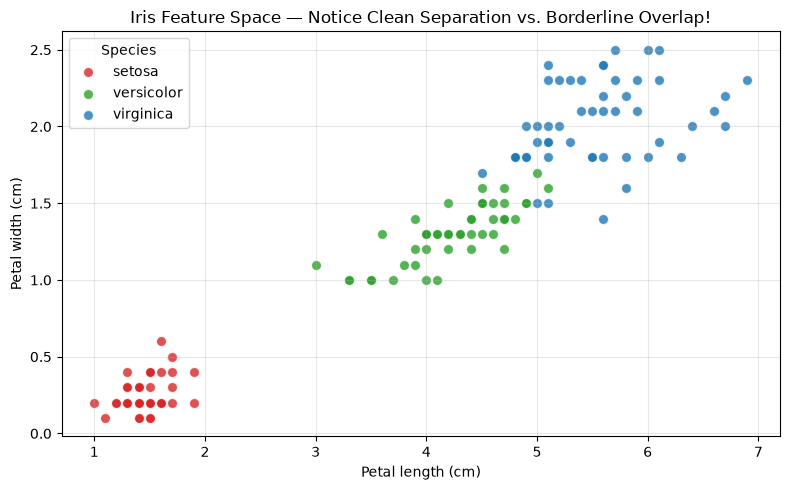

In [18]:
# Visualize two features: petal length vs. petal width
plt.figure(figsize=(8, 5))
palette = {"setosa": "#d62728", "versicolor": "#2ca02c", "virginica": "#1f77b4"}

for species in iris.target_names:
    sub = df[df["species"] == species]
    plt.scatter(
        sub["petal length (cm)"],
        sub["petal width (cm)"],
        c=palette[species],
        label=species,
        s=55,
        alpha=0.8,
        edgecolors="white",
    )

plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("Iris Feature Space — Notice Clean Separation vs. Borderline Overlap!")
plt.legend(title="Species")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4.1 🧠 Predict First! Why Not Test on the Training Data?

Before running the next cell, pause and think:
- Suppose a medical student memorizes the exact answers to 120 past exam questions word-for-word. If we test them on **those exact same 120 questions**, they score **100%** — even if they learned zero medicine!
- Look at `train_accuracy` vs. `test_accuracy` when we run the cell below. Why do they differ?

In [19]:
X = iris.data
y = iris.target

# Hold out 20% (30 unseen samples) as an independent test set
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X_train, y_train)

train_acc = accuracy_score(y_train, model.predict(X_train))
test_acc = accuracy_score(y_test, model.predict(X_test))

print(f"Training set ({len(X_train)} samples) accuracy : {train_acc:.1%}")
print(f"Unseen test set ({len(X_test)} samples) accuracy : {test_acc:.1%}")

Training set (120 samples) accuracy : 98.3%
Unseen test set (30 samples) accuracy : 96.7%


### 🎯 Your Turn! Test a Clear Case vs. a Borderline Case (Uncertainty!)

Look back at the green (`versicolor`) and blue (`virginica`) dots overlapping around `petal length ≈ 4.9 cm, petal width ≈ 1.6 cm` in the scatter plot.
- Run the cell below to inspect not only the predicted label (`model.predict`), but also the **class probabilities (`model.predict_proba`)**!
- Try nudging `borderline_sample`'s petal length from `5.0` down to `4.8` cm and watch the decision flip:

In [20]:
# Features: [sepal_length, sepal_width, petal_length, petal_width]
clear_sample = [[5.1, 3.5, 1.4, 0.2]]       # Clearly inside red (setosa) cluster
borderline_sample = [[6.0, 2.8, 5.0, 1.6]]  # Try changing 5.0 -> 4.8 or 1.6 -> 1.5!

for label, sample in [("Clear case", clear_sample), ("Borderline case", borderline_sample)]:
    pred_class = iris.target_names[model.predict(sample)[0]]
    probs = model.predict_proba(sample)[0]
    prob_str = ", ".join(f"{name}: {p:.0%}" for name, p in zip(iris.target_names, probs))
    print(f"{label:15s} -> Predicted: {pred_class:10s} | Probabilities: [{prob_str}]")

Clear case      -> Predicted: setosa     | Probabilities: [setosa: 100%, versicolor: 0%, virginica: 0%]
Borderline case -> Predicted: virginica  | Probabilities: [setosa: 0%, versicolor: 25%, virginica: 75%]


---

# Module 5: Patient Similarity Networks — Bridge to Lab 1 (12:05–12:30)

In **[Lab 1](https://github.com/arvidl/BMED365-2027/blob/main/Lab1-NetworkSci-PSN/README.md)**, instead of treating each patient as an isolated row in a spreadsheet, we model **relationships between patients** as a mathematical **graph (network)**:
- **Nodes** = patients (`Patient A` … `Patient E`)
- **Weighted edges** = clinical or molecular similarity between two patients (`0.0` to `1.0`)

Let's build a 5-patient similarity network with `NetworkX`:

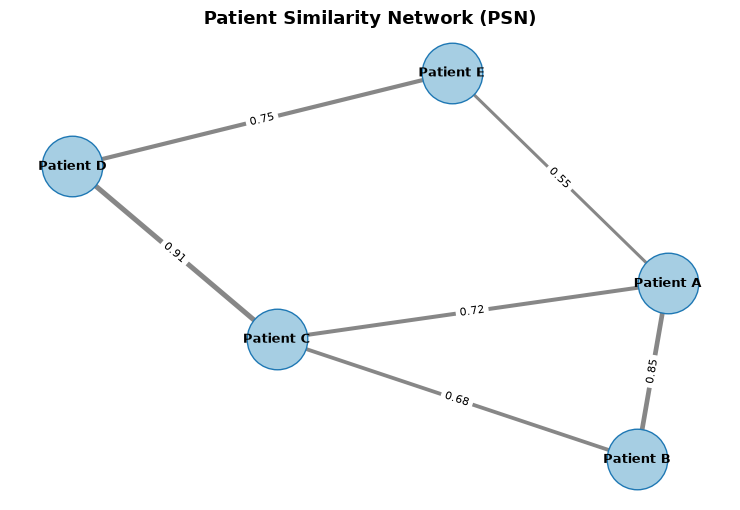

In [21]:
import networkx as nx

G = nx.Graph()
patients = ["Patient A", "Patient B", "Patient C", "Patient D", "Patient E"]
G.add_nodes_from(patients)

similarities = [
    ("Patient A", "Patient B", 0.85),
    ("Patient A", "Patient C", 0.72),
    ("Patient B", "Patient C", 0.68),
    ("Patient C", "Patient D", 0.91),  # Strongest pairwise similarity!
    ("Patient D", "Patient E", 0.75),
    ("Patient A", "Patient E", 0.55),
]

for p1, p2, sim in similarities:
    G.add_edge(p1, p2, weight=sim)

plt.figure(figsize=(7.5, 5.2))
pos = nx.spring_layout(G, seed=42)
widths = [G[u][v]["weight"] * 4 for u, v in G.edges()]

nx.draw_networkx_nodes(G, pos, node_color="#a6cee3", edgecolors="#1f78b4", node_size=1900)
nx.draw_networkx_labels(G, pos, font_size=9, font_weight="bold")
nx.draw_networkx_edges(G, pos, width=widths, alpha=0.7, edge_color="#555555")
edge_labels = {(u, v): f"{d['weight']:.2f}" for u, v, d in G.edges(data=True)}
nx.draw_networkx_edge_labels(G, pos, edge_labels, font_size=8)

plt.title("Patient Similarity Network (PSN)", fontsize=13, fontweight="bold")
plt.axis("off")
plt.tight_layout()
plt.show()

### 🧠 Predict First! Connection Count vs. Connection Strength

Look at the network diagram above **before** running the centrality cell below:
1. Which patient(s) have the **most connections** (*highest degree centrality*)?
2. Does `Patient D` — who shares the single strongest edge (`0.91` with `Patient C`) — have the highest *unweighted* degree centrality?

In [22]:
deg_centrality = nx.degree_centrality(G)
weighted_strength = dict(G.degree(weight="weight"))

print("Patient     | Degree Centrality | Weighted Similarity Sum")
print("-" * 57)
for p in sorted(G.nodes(), key=lambda n: deg_centrality[n], reverse=True):
    print(f"{p:11s} | {deg_centrality[p]:17.2f} | {weighted_strength[p]:23.2f}")

Patient     | Degree Centrality | Weighted Similarity Sum
---------------------------------------------------------
Patient A   |              0.75 |                    2.12
Patient C   |              0.75 |                    2.31
Patient B   |              0.50 |                    1.53
Patient D   |              0.50 |                    1.66
Patient E   |              0.50 |                    1.30


### 🎯 Your Turn! Add `Patient F` & Apply a Similarity Threshold
Add `Patient F` to a copy of the network, connect them to two patients, and test what happens if we prune weak edges below `0.70`:

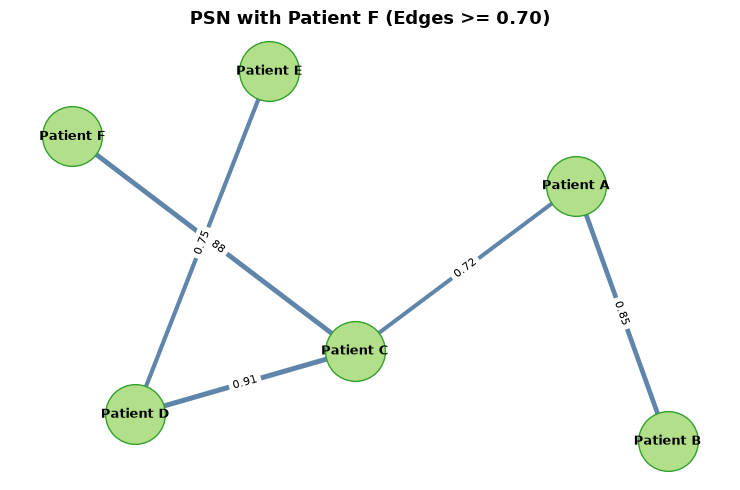

In [23]:
G_ext = G.copy()
G_ext.add_node("Patient F")
G_ext.add_edge("Patient F", "Patient C", weight=0.88)
G_ext.add_edge("Patient F", "Patient E", weight=0.62)  # Try changing 0.62 -> 0.80!

# Keep only strong similarity links (>= 0.70)
threshold = 0.70
G_strong = nx.Graph(
    [(u, v, d) for u, v, d in G_ext.edges(data=True) if d["weight"] >= threshold]
)
G_strong.add_nodes_from(G_ext.nodes())

plt.figure(figsize=(7.5, 5.0))
pos_ext = nx.spring_layout(G_ext, seed=42)
widths_s = [G_strong[u][v]["weight"] * 4 for u, v in G_strong.edges()]
nx.draw_networkx_nodes(G_strong, pos_ext, node_color="#b2df8a", edgecolors="#33a02c", node_size=1850)
nx.draw_networkx_labels(G_strong, pos_ext, font_size=9, font_weight="bold")
nx.draw_networkx_edges(G_strong, pos_ext, width=widths_s, alpha=0.75, edge_color="#2b5c8f")
nx.draw_networkx_edge_labels(
    G_strong, pos_ext, {(u, v): f"{d['weight']:.2f}" for u, v, d in G_strong.edges(data=True)}, font_size=8
)
plt.title(f"PSN with Patient F (Edges >= {threshold:.2f})", fontsize=13, fontweight="bold")
plt.axis("off")
plt.tight_layout()
plt.show()

---

# Module 6: Pixels, Voxels & Models — The Kiwi 7T MRI Challenge (12:30–12:50)

Remember the **7 Tesla kiwifruit MRI** from Lecture 1? Across **Block 2** of BMED365, that intact `'Hayward'` kiwifruit scanned at UiB (`256 × 256 × 128` voxels) serves as our hands-on bridge between:
- **[Lab 4 (Computational Imaging)](https://github.com/arvidl/BMED365-2027/blob/main/Lab4-Comp-Imag/Kiwi-challenge/README.md):** Segmenting and counting ~1,440 dark 3D seeds — directly analogous to quantifying **MS white-matter plaques**, **cerebral microbleeds**, or **3D cell nuclei** (*"lesion load"*).
- **[Lab 5 (Computational Modeling)](https://github.com/arvidl/BMED365-2027/blob/main/Lab5-Comp-Mod/Kiwi-challenge/README.md):** Modeling *how* seed-derived hormones, Turing patterns, and MRI spin-echo physics build that 3D organ (*Digital Twin*).

Let's load **equatorial slice `z = 64`** (`kiwi_064.png`) right now and see that a medical image is simply a **2D `NumPy` array of numbers**!

In [24]:
import pathlib
import urllib.request
from PIL import Image

KIWI_RAW_URL = (
    "https://raw.githubusercontent.com/arvidl/BMED365-2027/main/"
    "Lab4-Comp-Imag/Kiwi-challenge/data/kiwi_064.png"
)

def load_kiwi_slice() -> np.ndarray:
    """Load 16-bit 7T MRI slice locally, or download automatically in Google Colab."""
    for candidate in [
        pathlib.Path("../../Lab4-Comp-Imag/Kiwi-challenge/data/kiwi_064.png"),
        pathlib.Path("../Lab4-Comp-Imag/Kiwi-challenge/data/kiwi_064.png"),
        pathlib.Path("Lab4-Comp-Imag/Kiwi-challenge/data/kiwi_064.png"),
        pathlib.Path("kiwi_064.png"),
    ]:
        if candidate.exists():
            return np.array(Image.open(candidate))
    dst = pathlib.Path("kiwi_064.png")
    print("Downloading kiwi_064.png from BMED365-2027 GitHub for this session...")
    urllib.request.urlretrieve(KIWI_RAW_URL, dst)
    return np.array(Image.open(dst))

kiwi_slice = load_kiwi_slice()

print(f"Array shape (rows x cols) : {kiwi_slice.shape}")
print(f"Data type (bit depth)     : {kiwi_slice.dtype} (16-bit quantitative MRI!)")
print(f"Min / Max intensity       : {kiwi_slice.min()} / {kiwi_slice.max()}")
print(f"Center 10x10 core mean    : {kiwi_slice[123:133, 123:133].mean():.0f} (dark!)")

Array shape (rows x cols) : (256, 256)
Data type (bit depth)     : uint16 (16-bit quantitative MRI!)
Min / Max intensity       : 71 / 32766
Center 10x10 core mean    : 2902 (dark!)


## 6.1 🧠 Friction Lab: Why "Just Threshold Dark Pixels" (and Chatbot Counting) Fails!

In an optical kitchen photo of a sliced kiwifruit, the central core (*columella*) is **bright white**, while seeds are **black**.  
**Predict before running:** In this $T_2$-weighted 7T MRI slice (`TE = 63.9 ms`), dense fibrous core tissue has a short $T_2$ relaxation time and appears **dark** — just like the seeds!

What happens if we (or a naive AI script) try to detect seeds Inside the fruit by simply picking dark intensities (`1,200 < intensity < 5,500`)?

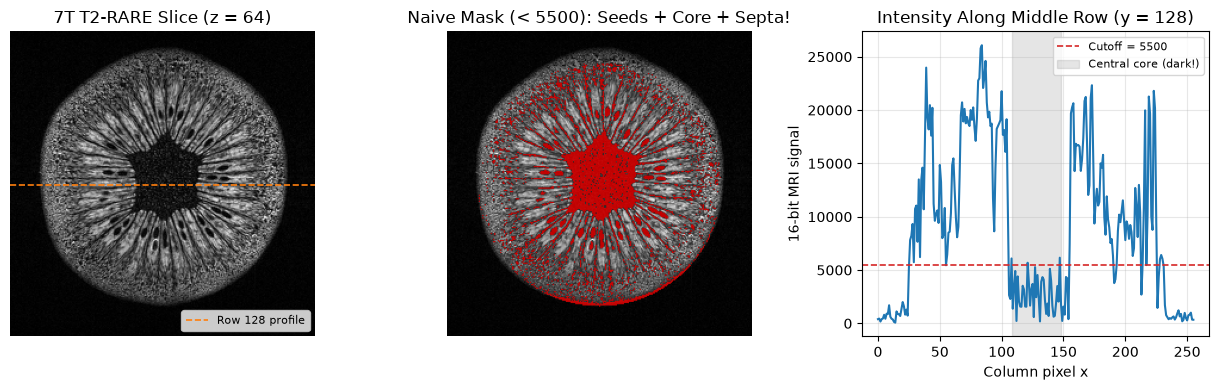

Flagged 'dark' pixels inside circle: 7259 pixels


In [25]:
# ============================================================================
# VISUALIZING LECTURE 1 TRAP 1: NAIVE DARKNESS THRESHOLDING ON 7T MRI
# ============================================================================
def inspect_naive_seed_threshold(dark_cutoff: int = 5500):
    # Rough fruit interior mask (exclude dark background air outside the peel)
    yy, xx = np.ogrid[:256, :256]
    inside_fruit = ((yy - 128) ** 2 + (xx - 128) ** 2) <= (102 ** 2)
    naive_dark_mask = inside_fruit & (kiwi_slice < dark_cutoff)

    fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.0))

    axes[0].imshow(kiwi_slice, cmap="gray")
    axes[0].axhline(128, color="#ff7f0e", ls="--", lw=1.2, label="Row 128 profile")
    axes[0].set_title("7T T2-RARE Slice (z = 64)")
    axes[0].legend(loc="lower right", fontsize=8)
    axes[0].axis("off")

    axes[1].imshow(kiwi_slice, cmap="gray")
    axes[1].imshow(np.ma.masked_where(~naive_dark_mask, naive_dark_mask), cmap="autumn", alpha=0.75)
    axes[1].set_title(f"Naive Mask (< {dark_cutoff}): Seeds + Core + Septa!")
    axes[1].axis("off")

    axes[2].plot(kiwi_slice[128, :], color="#1f77b4", lw=1.5)
    axes[2].axhline(dark_cutoff, color="#d62728", ls="--", lw=1.2, label=f"Cutoff = {dark_cutoff}")
    axes[2].axvspan(108, 148, color="gray", alpha=0.2, label="Central core (dark!)")
    axes[2].set_title("Intensity Along Middle Row (y = 128)")
    axes[2].set_xlabel("Column pixel x")
    axes[2].set_ylabel("16-bit MRI signal")
    axes[2].legend(fontsize=8)
    axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()
    print(f"Flagged 'dark' pixels inside circle: {int(naive_dark_mask.sum())} pixels")

inspect_naive_seed_threshold(dark_cutoff=5500)

<details>
<summary><b>🔍 Friction Check — Why can't we just ask a Vision LLM "How many seeds are in <code>kiwi_064.png</code>?"</b></summary>

1. **2D vs. 3D:** This PNG is just **1 of 128 axial slices**! Counting 2D cross-sections slice-by-slice overcounts seeds that span 3–5 slices (*Wicksell's stereological fallacy*).
2. **Confident hallucination:** Multimodal chatbots output a fluent guess (e.g., *"There are 87 seeds"*), yet give a different integer if you rotate the image by 90°!
3. **The BMED365 lesson:** Don't ask AI to *eyeball* quantitative biomarkers — collaborate with AI to **write and verify reproducible 3D Python code** (which we master in **Lab 4**!).
</details>

---

## 6.2 From 3D Voxels (`mm³`) to a 1-Line Organ Growth Model (`Lab 4 → Lab 5`)

In 3D MRI, each pixel has slice thickness, making it a 3D **voxel** (*volume element*):
- In-plane spacing: `0.2344 mm × 0.2344 mm`
- Slice thickness: `0.5000 mm` (**anisotropic** — more than $2\times$ thicker along $z$!)

And in **Lab 5**, we discover that developing kiwifruit seeds release growth hormones (auxin/cytokinin) that expand fruit volume $V(N)$ via the **exact same receptor-saturation equation ($E_{\max}$ / Hill curve)** used in human pharmacology:

$$V(N) = V_{\text{basal}} + V_{\max}\,\frac{N}{K_N + N}$$

Let's compute the physical voxel geometry and test this 1-line biophysical model against our real 2005 7T MRI scan (`85.97 cm³` at `N ≈ 1,440` seeds)!

Single 3D voxel volume         : 0.0275 mm^3 (~60 voxels per seed)
Estimated 'lesion load' (seeds): 2.76% of whole-fruit volume


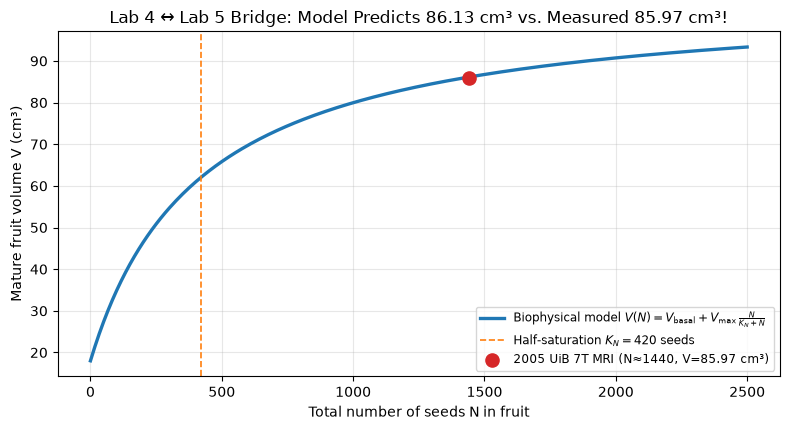

In [26]:
# 1. 3D Voxel Geometry & "Lesion Load" (Lab 4 Quantitative Biomarker)
dx_mm, dy_mm, dz_mm = 0.2344, 0.2344, 0.5000
voxel_vol_mm3 = dx_mm * dy_mm * dz_mm

measured_fruit_cm3 = 85.97          # From 3D 7T MRI mask (Lab 4)
n_seeds_calibrated = 1440           # Calibrated 3D seed count (Lab 4 Notebook 03)
mean_seed_vol_mm3 = 1.65            # Typical single seed (~60 voxels)
total_seed_vol_cm3 = (n_seeds_calibrated * mean_seed_vol_mm3) / 1000.0
lesion_load_pct = (total_seed_vol_cm3 / measured_fruit_cm3) * 100.0

print(f"Single 3D voxel volume         : {voxel_vol_mm3:.4f} mm^3 (~{mean_seed_vol_mm3 / voxel_vol_mm3:.0f} voxels per seed)")
print(f"Estimated 'lesion load' (seeds): {lesion_load_pct:.2f}% of whole-fruit volume")

# 2. Mechanistic Seed-Hormone Receptor Saturation Curve (Lab 5 Stage 1)
def predict_kiwi_volume_cm3(n_seeds):
    v_basal = 18.0  # cm^3 unpollinated baseline
    v_max = 88.0    # cm^3 max hormone-driven expansion
    k_n = 420.0     # half-saturation seed count (analogous to EC50!)
    return v_basal + v_max * (n_seeds / (k_n + n_seeds))

n_grid = np.linspace(0, 2500, 300)
v_curve = predict_kiwi_volume_cm3(n_grid)
v_pred_1440 = predict_kiwi_volume_cm3(n_seeds_calibrated)

plt.figure(figsize=(8.0, 4.4))
plt.plot(n_grid, v_curve, lw=2.4, color="#1f77b4", label=r"Biophysical model $V(N) = V_{\mathrm{basal}} + V_{\max}\frac{N}{K_N + N}$")
plt.axvline(420, ls="--", color="#ff7f0e", lw=1.2, label="Half-saturation $K_N = 420$ seeds")
plt.scatter([n_seeds_calibrated], [measured_fruit_cm3], color="#d62728", s=90, zorder=5,
            label=f"2005 UiB 7T MRI (N≈{n_seeds_calibrated}, V={measured_fruit_cm3:.2f} cm³)")
plt.xlabel("Total number of seeds N in fruit")
plt.ylabel("Mature fruit volume V (cm³)")
plt.title(f"Lab 4 ↔ Lab 5 Bridge: Model Predicts {v_pred_1440:.2f} cm³ vs. Measured {measured_fruit_cm3:.2f} cm³!")
plt.legend(fontsize=8.5)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 🎯 Your Turn! Run an *In Silico* Pollination Experiment

What happens if poor bee pollination leaves a flower with only `N = 120` seeds versus a super-pollinated flower with `N = 2,800` seeds?  
**Predict first:** Does doubling seeds from `1,400` to `2,800` double the fruit size? Run the cell below to check!

In [27]:
# Try any seed counts you like!
for n_test in [0, 120, 420, 1440, 2800]:
    print(f"N = {n_test:4d} seeds -> Predicted fruit volume = {predict_kiwi_volume_cm3(n_test):5.1f} cm^3")

N =    0 seeds -> Predicted fruit volume =  18.0 cm^3
N =  120 seeds -> Predicted fruit volume =  37.6 cm^3
N =  420 seeds -> Predicted fruit volume =  62.0 cm^3
N = 1440 seeds -> Predicted fruit volume =  86.1 cm^3
N = 2800 seeds -> Predicted fruit volume =  94.5 cm^3


---

# Module 7: Summary, Self-Check & The Road Ahead (12:50–13:00)

## What You Built Today

| Module | Core Skill | Friction Lesson |
|:-------|:-----------|:----------------|
| **1. Setup & Mindset** | Colab / local `uv` (`bmed365-2027`), `print()` | `"120" + "80"` vs. `120 + 80` — types matter! |
| **2. Python Basics** | Variables, BMI & MAP, lists (`0`-indexed), `if/for/def` | Always carry physical/clinical units in variable names |
| **3. AI Partner** | *Centaur* & *Cyborg* prompting, reading tracebacks | Code that *runs* can still harbor silent clinical bugs (`168 cm`, `> 38.0`) |
| **4. Machine Learning** | `pandas`, `DecisionTreeClassifier`, `predict_proba` | Never evaluate accuracy on training data; inspect borderline uncertainty |
| **5. Networks (PSN)** | `NetworkX` nodes, weighted edges, centrality | Most connections $\neq$ strongest single connection |
| **6. Kiwi 7T MRI Bridge** | 16-bit 2D `NumPy` slice, 3D voxels (`mm³`), $E_{\max}$ model | Darkness $\neq$ seed; receptor saturation buffers biological size |

---

## 🧠 60-Second Retrieval Practice (Test Yourself *Without* AI!)

<details>
<summary><b>1. If <code>temps = [36.6, 37.9, 38.4]</code>, what does <code>temps[0]</code> return, and what does <code>temps[-1]</code> return?</b></summary>

`temps[0]` returns the **first** item (`36.6`), and `temps[-1]` returns the **last** item (`38.4`).
</details>

<details>
<summary><b>2. Why did naive dark-pixel thresholding fail on the 7T kiwifruit MRI slice?</b></summary>

Because in $T_2$-weighted RARE MRI, the optically white fibrous central core (*columella*) and outer peel also have low signal (short $T_2$), so intensity thresholding merges seeds with non-seed anatomy.
</details>

<details>
<summary><b>3. What is the difference between using AI as a "crutch" vs. in "Cyborg/Centaur" mode?</b></summary>

A crutch bypasses thinking "I accept the result without adequately understanding or evaluating it" (copy-pasting unverified answers, leading to *never-skilling*). In Cyborg/Centaur mode, *you* predict first, specify clinical/physical constraints, read tracebacks, and verify edge cases against reality.
</details>

---

## The Road Ahead in BMED365 (Spring 2027)

- **[Lab 0 (Machine Learning)](https://github.com/arvidl/BMED365-2027/blob/main/Lab0-ML/README.md)** & **[Lab 1 (Network Science & PSN)](https://github.com/arvidl/BMED365-2027/blob/main/Lab1-NetworkSci-PSN/README.md)** — Full clinical classification & patient similarity networks
- **[Lab 2 (Deep Learning, Jan 15)](https://github.com/arvidl/BMED365-2027/blob/main/Lab2-DL/README.md)** — Neural networks, CNNs for ECG & medical images, Grad-CAM explainability, and TabPFN
- **[Lab 3 (Generative AI & LLMs, Jan 19)](https://github.com/arvidl/BMED365-2027/blob/main/Lab3-GenAI-LLM/README.md)** — Transformers, prompt/context engineering, XAI, EU AI Act ethics, trustworthy & neurosymbolic AI
- **[Team Project (Glioblastoma Precision Medicine)](https://github.com/arvidl/BMED365-2027/blob/main/Team-project/README.md)** — Interdisciplinary research proposal (presentations Jan 26)
- **[Lab 4 (Computational Imaging, Feb 8)](https://github.com/arvidl/BMED365-2027/blob/main/Lab4-Comp-Imag/README.md)** — Brain mpMRI glioma, IMC, & the **[Kiwi 3D Seed Segmentation Challenge](https://github.com/arvidl/BMED365-2027/blob/main/Lab4-Comp-Imag/Kiwi-challenge/README.md)**
- **[Lab 5 (Computational Modeling, Feb 19)](https://github.com/arvidl/BMED365-2027/blob/main/Lab5-Comp-Mod/README.md)** — Physiological ODEs/PDEs & the **[Kiwi Morphogenesis & 7T MRI Digital Twin](https://github.com/arvidl/BMED365-2027/blob/main/Lab5-Comp-Mod/Kiwi-challenge/README.md)**
- **[Individual Project](https://github.com/arvidl/BMED365-2027/blob/main/Individual-project/README.md)** — Your own computational biomedicine speed-poster investigation!

---

*Questions? Contact [Arvid Lundervold](https://www.uib.no/en/persons/Arvid.Lundervold) · Department of Biomedicine & MMIV, University of Bergen*